# 04 — Disección instrumentada de SAM 2.1 y DINOv3

**Solo etapa 4; ejecución por el usuario exclusivamente en Colab con GPU.** No ejecutar modelos en la PC, tampoco en CPU. No entrenamiento, probe, prompts automáticos, métricas de calidad, reservados ni demo.

Reutiliza las etapas 1–3: entorno, SAM tiny, datos y estadísticas train por régimen, transforms, geometría y persistencia verificada. DINOv3 ViT-L/16 SAT-493M congelado, revisión autorizada `f692fa42da72c6797b67cd73494a168d1120d3ee`. Conserva la salvedad histórica de licencia de datos.

Fuentes: bases del curso, sección A y política IA; resumen WAIMLAP, metodología y evaluación; hoja de ruta, §§2.4 y etapa 4. Instrucciones completas: `docs/project/validacion_etapa4.md` en el paquete.


## Hipótesis y protocolo previo

H4a: el encoder de imagen dominará la aritmética cubierta de SAM; sus módulos de vídeo siguen teniendo parámetros aunque no se ejecuten. H4b: atención global de DINOv3 permitirá sensibilidad distante no uniforme. H4c: FLOPs parciales y latencia no serán equivalentes por tráfico, operaciones sin fórmula y kernels.

Dos chips train por régimen, primeros IDs lexicográficos, sin etiquetas. RGB B4/B3/B2 y límites radiométricos de etapa 2 sin reajustarlos; SAM 1024 y DINO 512. Batch 1, float32, sin autocast/TF32, semilla 42; 5 warmups y 20 repeticiones sincronizadas. Puntos diagnósticos espaciales fijos (256,256)+ y (32,32)−, sin interpretación semántica ni calidad de segmentación. No cambies estas decisiones después de ver las imágenes.

Parámetros por propiedad exclusiva con residual; FLOPs PyTorch con 2 operaciones por multiply-add, cobertura parcial listada dinámicamente. Features Hiera de primer/medio/último bloque y DINO capas 0/11/23 más salida normalizada. CLS=0, registros después, parches restantes en orden de filas. Visualización de canales 0/1/2; sin PCA ni proyección aprendida. ERF: gradiente absoluto RGB respecto a entrada normalizada, canal 0 espacial central, masa unitaria; no campo receptivo teórico.


## 1. Paquete y entorno

En la PC: `python scripts/export_stage4_bundle.py`. Sube el ZIP de fuentes a Drive, abre este notebook en Colab y selecciona GPU. Copia su SHA-256 debajo. Usa la raíz persistente histórica con `raw/`, `stage2/` y manifiestos/preprocesamiento por régimen. La revisión gated requiere tu token autorizado de Hugging Face si no está en caché; usa el secreto `HF_TOKEN` de Colab sin imprimirlo.


In [1]:
from pathlib import Path
import hashlib, json, os, subprocess, sys, zipfile
from google.colab import drive

drive.mount('/content/drive')
PERSIST_ROOT = '/content/drive/MyDrive/auto-prompt-sam2'
REPO = Path('/content/auto-prompt-sam2-stage4')
PYTHON = Path('/content/auto-prompt-venv/bin/python')
BUNDLE = Path('/content/drive/MyDrive/auto-prompt-sam2-stage4.zip')
EXPECTED_BUNDLE_SHA256 = 'd7d71e0a2dd9255de3b1e0e6ef835335947fa52be903c3e8824e9cae7323b7f0'  # Copiar salida de export_stage4_bundle.py.
assert len(EXPECTED_BUNDLE_SHA256) == 64, 'Configura el SHA-256 del paquete.'
assert hashlib.sha256(BUNDLE.read_bytes()).hexdigest() == EXPECTED_BUNDLE_SHA256
REPO.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(BUNDLE) as archive:
    for item in archive.infolist():
        assert (REPO / item.filename).resolve().is_relative_to(REPO.resolve())
    archive.extractall(REPO)
child_env = dict(os.environ, PYTHONPATH=str(REPO / 'src'),
    AUTO_PROMPT_PERSIST_ROOT=PERSIST_ROOT, PYTHONHASHSEED='42',
    CUBLAS_WORKSPACE_CONFIG=':4096:8',
    AUTO_PROMPT_EXECUTION_CONTEXT='google_colab_user_notebook')
# Token opcional para descarga autorizada, nunca imprimirlo ni incluirlo en informes.
from google.colab import userdata
try:
    child_env['HF_TOKEN'] = userdata.get('HF_TOKEN')
except userdata.SecretNotFoundError:
    print('HF_TOKEN no configurado; se usara la cache autorizada si existe.')
LOG_DIR = Path(PERSIST_ROOT) / 'stage4/notebook_logs'
LOG_DIR.mkdir(parents=True, exist_ok=True)
def command(args, log_name):
    with (LOG_DIR / log_name).open('w', encoding='utf-8') as log:
        process = subprocess.Popen(args, cwd=REPO, env=child_env, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        for line in process.stdout:
            print(line, end='')
            log.write(line)
            log.flush()
        result = process.wait()
    if result:
        raise RuntimeError(f'Proceso terminado con código {result}; conservar salida y log {log_name}')
if not PYTHON.is_file():
    command([sys.executable, str(REPO / 'scripts/bootstrap_colab.py')], 'bootstrap.log')
command([str(PYTHON), '-m', 'pip', 'install', '--no-deps', '-r', str(REPO / 'requirements-stage2.txt')], 'stage2_pins.log')
command([str(PYTHON), '-m', 'pip', 'check'], 'pip_check.log')


Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 10.6 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 117.5 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 34.7 MB/s  0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 35.3 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 66.3 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 150.8 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 54.3 MB/s  0:00:05
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 62.5 MB/

## 2. Preparar y medir en Colab

Ejecuta `prepare` una vez. Carga SAM y DINO secuencialmente para limitar VRAM; no cambia modelo, precisión o tamaño ante OOM. Un fallo guarda diagnóstico y generaciones completas; conserva el ZIP, corrige el recurso en Colab y usa `prepare` para un run nuevo. Las mediciones se hacen sobre el primer train de cada régimen; las features/ERF sobre ambos.

El flujo SAM tensorial se contrasta con el predictor reutilizado de etapa 3. Los tiempos excluyen descarga/carga de pesos, TIFF, transforms CPU, H2D/D2H, hooks, gradientes, guardado y figuras. SAM incluye encoder, proyecciones conv_s0/s1, no_mem, prompts, dense PE, decoder y logits a 512. DINO incluye embeddings, RoPE, 24 capas y norma final. El replay aislado de bloques no es aditivo y declara su baseline de memoria. El flujo automático completo aún no existe.


In [2]:
command([str(PYTHON), str(REPO / 'scripts/run_stage4.py'), 'prepare', '--root', PERSIST_ROOT], 'prepare.log')


fatal: not a git repository (or any of the parent directories): .git
 test_canonical_hash (test_stage1.PersistenceTests.test_canonical_hash) ... ok
test_colab_temporary_root_blocked (test_stage1.PersistenceTests.test_colab_temporary_root_blocked) ... ok
test_each_identity_change_is_rejected (test_stage1.PersistenceTests.test_each_identity_change_is_rejected) ... ok
test_export_reports_absent_access_instead_of_claiming_authorization (test_stage1.PersistenceTests.test_export_reports_absent_access_instead_of_claiming_authorization) ... ok
test_export_uses_saved_identity_and_only_verified_json (test_stage1.PersistenceTests.test_export_uses_saved_identity_and_only_verified_json) ... ok
test_head_never_logs_token_or_follows_redirect (test_stage1.PersistenceTests.test_head_never_logs_token_or_follows_redirect) ... ok
test_incomplete_and_corrupt_generation_preserve_previous (test_stage1.PersistenceTests.test_incomplete_and_corrupt_generation_preserve_previous) ... ok
test_no_path_escape (test_

## 3. Inspeccionar evidencia real

Revisa tablas y figuras. Los colores de cada canal usan min/max del panel; el ERF usa color logarítmico y overlay sobre RGB train. Los arrays crudos y los rangos se guardan. No interpretes canales como probabilidad de agua. Las columnas FLOPs nulas indican módulos no llamados; los ceros del contador no acreditan costo real cero.


run_id: 20261029T162558Z_bfb5852907_c4c91701
{
  "ai_use": "Codex prepared instrumentation, notebook, contracts and documentation; no GPU result fabricated. Human execution and evidence review required.",
  "findings": "Observed block arithmetic shares quantify where covered work occurs; null blocks were not executed. ERF outside-center mass measures nonuniform distant sensitivity for these fixed targets. Cross-model timing uses different resolutions/outputs and cannot rank water quality; human/assistant visual review and hypothesis conclusions pending.",
  "hypotheses": [
    "Image encoder dominates SAM static arithmetic; memory modules remain present.",
    "Deep global-attention DINO features can have nonuniform distant sensitivity.",
    "Latency is not determined by counted FLOPs alone."
  ],
  "limits": "Two lexicographic train chips per regime; fixed diagnostic spatial points are not semantic prompts. No water quality metric, learned projection, probe, decoder training or autom

block,executed_calls,counted_flops
embeddings,1,1610612736
rope_embeddings,1,0
layer.0,1,30232645632
layer.1,1,30232645632
layer.2,1,30232645632
layer.3,1,30232645632
layer.4,1,30232645632
layer.5,1,30232645632
layer.6,1,30232645632
layer.7,1,30232645632


dino_leave_paraguay_out_0_timings.csv


block,median_ms,min_ms,max_ms,warmup,repetitions,baseline_allocated_bytes,baseline_reserved_bytes,peak_allocated_bytes,peak_reserved_bytes,incremental_peak_allocated_bytes,scope,batch_size,precision,autocast,synchronization,cache,calls_in_full_path
full_static_path,262.6700084999811,257.9165769999463,267.5084190000234,5,20,1283830272,2533359616,1331745280,2533359616,47915008,preloaded_inputs_and_weights_no_hooks_no_io_no_backward,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,
embeddings,0.7555755000225872,0.7046919999993406,0.9113330000900532,5,20,1286976000,2533359616,1295385088,2533359616,8409088,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
rope_embeddings,0.2538134999667818,0.2358610000783301,0.3234009999459886,5,20,1286976000,2533359616,1287762432,2533359616,786432,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
layer.0,10.530338000023676,9.528785000043172,17.089188999989346,5,20,1289597440,2533359616,1331745280,2533359616,42147840,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
layer.1,10.440664500094954,9.407866999936232,14.763624000011077,5,20,1289597440,2533359616,1331745280,2533359616,42147840,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
layer.2,10.703404999958366,10.535853000078532,10.997817999964354,5,20,1289597440,2533359616,1331745280,2533359616,42147840,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
layer.3,10.579138499963392,10.342844000092555,11.318528999936461,5,20,1289597440,2533359616,1331745280,2533359616,42147840,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
layer.4,10.43492100001231,10.315920000039114,11.224935000086589,5,20,1289597440,2533359616,1331745280,2533359616,42147840,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
layer.5,10.781018500040318,10.317044000089481,12.132110000038665,5,20,1289597440,2533359616,1331745280,2533359616,42147840,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1
layer.6,10.92187899990904,10.486167000067326,11.312675999988642,5,20,1289597440,2533359616,1331745280,2533359616,42147840,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1


dino_official_0_flops.csv


...

sam_official_0_timings.csv


block,median_ms,min_ms,max_ms,warmup,repetitions,baseline_allocated_bytes,baseline_reserved_bytes,peak_allocated_bytes,peak_reserved_bytes,incremental_peak_allocated_bytes,scope,batch_size,precision,autocast,synchronization,cache,calls_in_full_path,status
full_static_path,148.59552950002808,145.87549499992747,149.49467600001753,5,20,382429696,2191523840,684419584,2191523840,301989888,preloaded_inputs_and_weights_no_hooks_no_io_no_backward,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,,
image_encoder,122.67841400000634,120.01493399998253,125.20615999994789,5,20,395012608,2191523840,697002496,2191523840,301989888,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1,
sam_prompt_encoder,1.4928824999742574,1.467086000047857,1.6297669999403297,5,20,382430720,2191523840,382443008,2191523840,12288,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1,
sam_mask_decoder,30.89920850004546,30.465022000043973,35.30749799995192,5,20,407598592,2191523840,437043712,2191523840,29445120,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1,
memory_attention,,,,,,,,,,,,,,,,,,not_executed_static_image_path
memory_encoder,,,,,,,,,,,,,,,,,,not_executed_static_image_path
obj_ptr_proj,,,,,,,,,,,,,,,,,,not_executed_static_image_path
obj_ptr_tpos_proj,,,,,,,,,,,,,,,,,,not_executed_static_image_path


sam_parameters.csv


block,parameters,trainable
image_encoder,27219136,0
sam_prompt_encoder,6220,0
sam_mask_decoder,4215109,0
memory_attention,5922304,0
memory_encoder,1384608,0
obj_ptr_proj,197376,0
obj_ptr_tpos_proj,16448,0
residual,1297,0


dino_leave_paraguay_out_0_figure.png


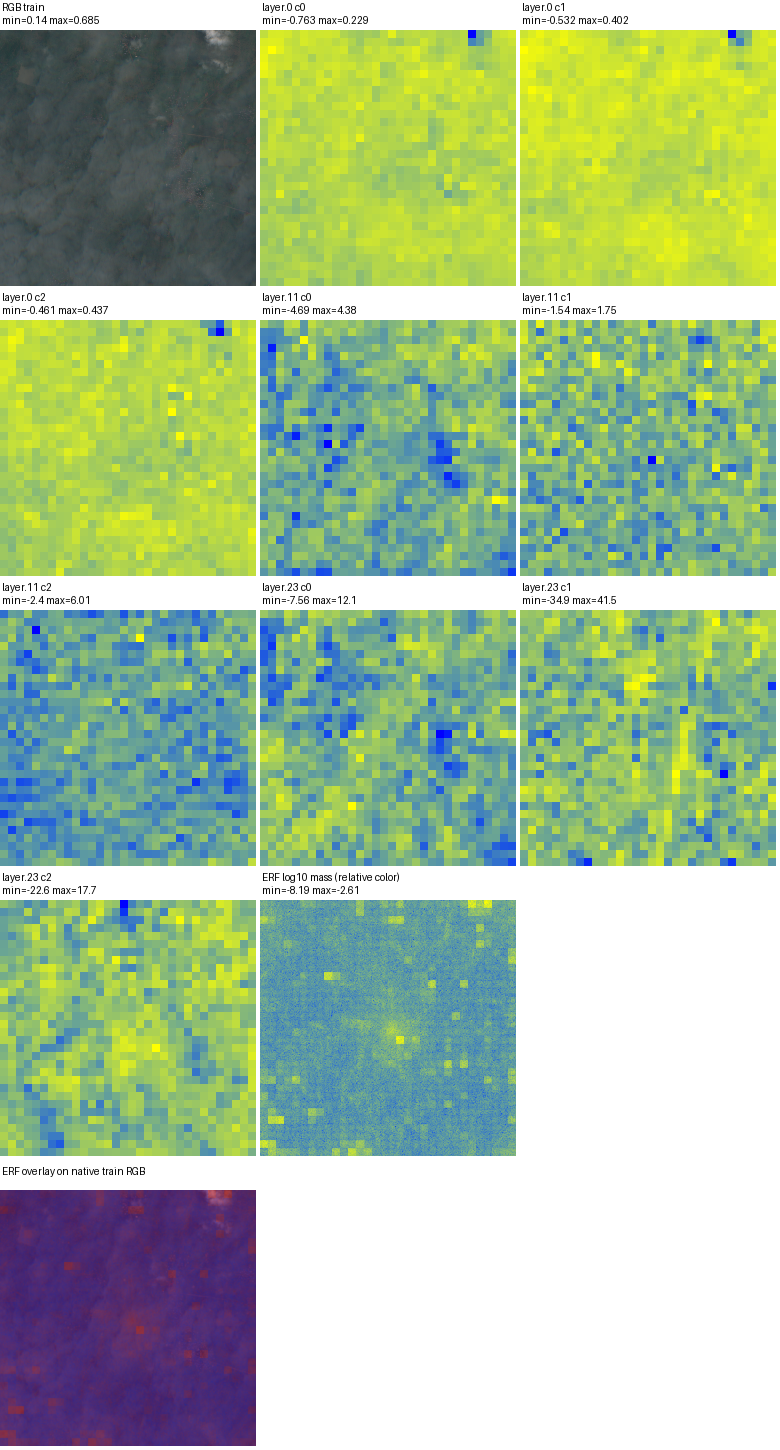

dino_official_0_figure.png


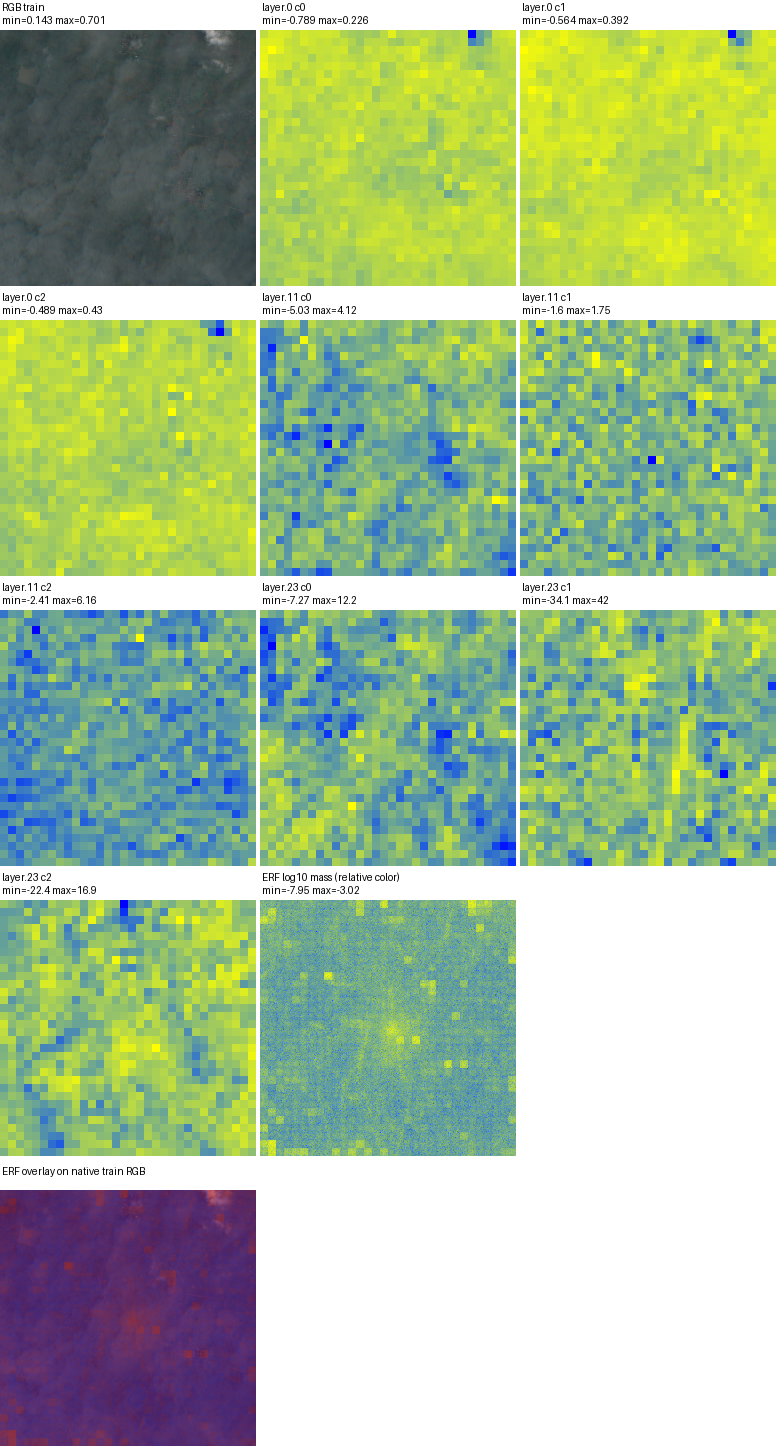

sam_leave_paraguay_out_0_figure.png


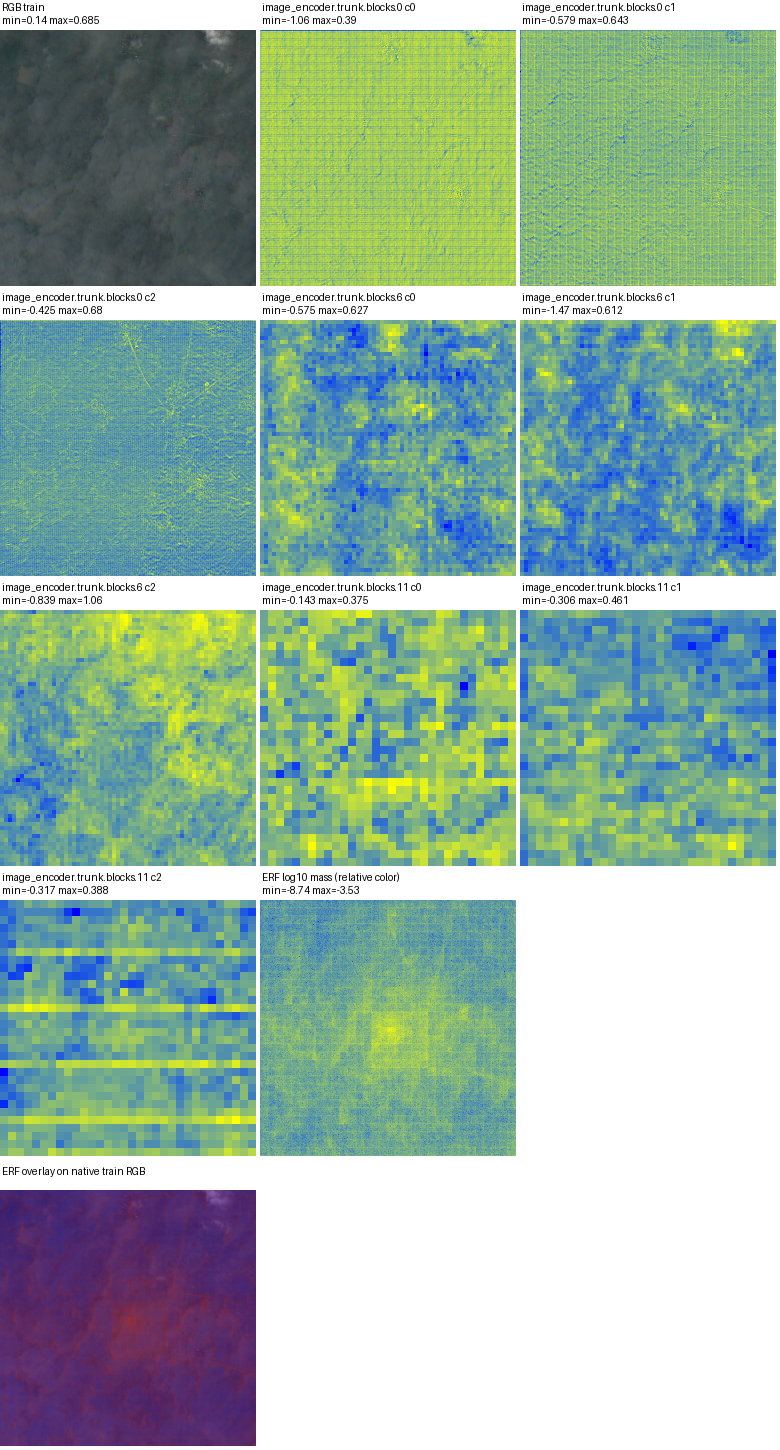

sam_official_0_figure.png


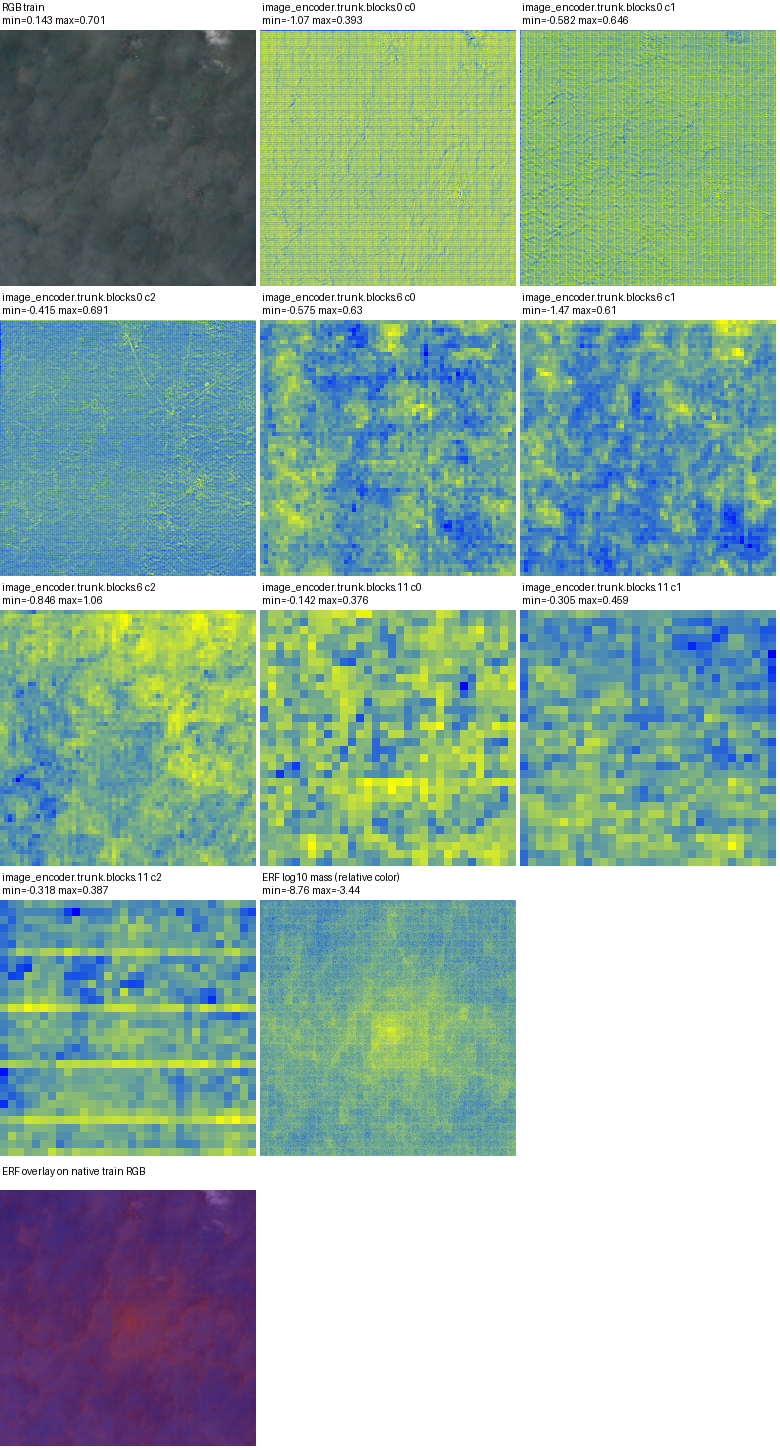

Todos los arrays, metadatos y figuras: /content/drive/MyDrive/auto-prompt-sam2/stage4/evidence/20261029T162558Z_bfb5852907_c4c91701.zip


In [3]:
from IPython.display import display, Image, HTML
import csv, html
EVIDENCE = Path(PERSIST_ROOT) / 'stage4/evidence'
RUNS = sorted(p for p in EVIDENCE.iterdir() if p.is_dir() and (p / 'validation.json').is_file())
assert RUNS, 'No hay prepare completo; conserva logs y failure.json.'
RUN_DIR = RUNS[-1]
REPORT = json.loads((RUN_DIR / 'validation.json').read_text())
print('run_id:', REPORT['run_id'])
print(json.dumps(REPORT['interpretation'], indent=2, ensure_ascii=False))
for table in sorted(RUN_DIR.glob('*.csv')):
    rows = list(csv.reader(table.open(encoding='utf-8', newline='')))
    print(table.name)
    display(HTML('<table>' + ''.join('<tr>' + ''.join('<td>' + html.escape(v) + '</td>' for v in row) + '</tr>' for row in rows) + '</table>'))
for figure in sorted(RUN_DIR.glob('*_0_figure.png')):
    print(figure.name)
    display(Image(filename=str(figure)))
print('Todos los arrays, metadatos y figuras:', RUN_DIR.with_suffix('.zip'))


## 4. Recuperación offline tras eliminar el runtime

Guarda el notebook **con salidas**, desconecta y elimina el runtime desde Colab, vuelve a seleccionar GPU y ejecuta solo la celda de entorno de la sección 1 y la celda `recover` siguiente. No repitas `prepare`: crearía otro run. Mantén ZIP, SHA, config y raíz idénticos. Se reconstruye el entorno, se recargan los pesos en caché persistente con `local_files_only=True`, se verifican todas las generaciones y se repiten features/ERF en los mismos train con atol=1e-5/rtol=1e-4. No se vuelven a medir latencias para sustituir las originales. Un boot ID distinto es obligatorio. No ejecutar las celdas prepare/inspección en esta segunda sesión; sus salidas previas deben conservarse.


In [2]:
command([str(PYTHON), str(REPO / 'scripts/run_stage4.py'), 'recover', '--root', PERSIST_ROOT], 'recover.log')


fatal: not a git repository (or any of the parent directories): .git
 test_canonical_hash (test_stage1.PersistenceTests.test_canonical_hash) ... ok
test_colab_temporary_root_blocked (test_stage1.PersistenceTests.test_colab_temporary_root_blocked) ... ok
test_each_identity_change_is_rejected (test_stage1.PersistenceTests.test_each_identity_change_is_rejected) ... ok
test_export_reports_absent_access_instead_of_claiming_authorization (test_stage1.PersistenceTests.test_export_reports_absent_access_instead_of_claiming_authorization) ... ok
test_export_uses_saved_identity_and_only_verified_json (test_stage1.PersistenceTests.test_export_uses_saved_identity_and_only_verified_json) ... ok
test_head_never_logs_token_or_follows_redirect (test_stage1.PersistenceTests.test_head_never_logs_token_or_follows_redirect) ... ok
test_incomplete_and_corrupt_generation_preserve_previous (test_stage1.PersistenceTests.test_incomplete_and_corrupt_generation_preserve_previous) ... ok
test_no_path_escape (test_

## 5. Entrega para revisión y parada

Comparte el notebook descargado con salidas y errores/orden conservados; el ZIP `stage4/evidence/<run_id>.zip`; `validation.json`, `recovery_validation.json`, `config.json`, `environment.json`; y los logs de `stage4/notebook_logs/` si hubo problemas. No compartas tokens ni pesos. Si falla un paso, comparte su evidencia y no avances de etapa.

El asistente verificará hashes, revisiones, train por régimen, parámetros/FLOPs, tiempos/memoria, hooks, pesos, recuperación y figuras; contrastará H4a–c con las medidas y actualizará cuaderno/estado. El marcador `complete` acredita cómputo, **no cierre académico de etapa**. La etapa 4 permanece en curso hasta esa revisión. Detener aquí; no ejecutar etapas 5–9 ni demo.


In [3]:
RECOVERY_RUNS = sorted(p for p in (Path(PERSIST_ROOT) / 'stage4/evidence').iterdir() if p.is_dir() and (p / 'recovery_validation.json').is_file())
assert RECOVERY_RUNS
recovery = json.loads((RECOVERY_RUNS[-1] / 'recovery_validation.json').read_text())
print(json.dumps({'run_id': recovery['run_id'], 'status': recovery['status'], 'different_runtime_boot': recovery['different_runtime_boot'], 'closure': recovery['closure'], 'evidence_zip': str(RECOVERY_RUNS[-1].with_suffix('.zip'))}, indent=2))


{
  "run_id": "20261029T162558Z_bfb5852907_c4c91701",
  "status": "computation_passed_pending_external_review",
  "different_runtime_boot": true,
  "closure": "pending_external_review_of_user_notebook_json_tables_and_figures",
  "evidence_zip": "/content/drive/MyDrive/auto-prompt-sam2/stage4/evidence/20261029T162558Z_bfb5852907_c4c91701.zip"
}
